# 01: Pair Selection via Cointegration

In this notebook I walk through the statistical pipeline that decides
*which pairs are tradeable*, step by step, using **training data only**
(years 1 to 3). Nothing here touches the validation or test years, and I
explain why that restriction matters at the end.

**The idea in plain English.** Two stocks in the same sector are often
driven by the same economics. Each stock's price on its own wanders like
a random walk: knowing where it is today tells me almost nothing about
where it settles long-term. But a particular *combination* of the two
(long one, short a fixed multiple of the other) can be stable. When that
combination strays far from its typical level, it tends to come back.
Such a combination is called a **cointegrated spread**, and "tends to
come back" is the property I trade.

Note that this is a stronger requirement than correlation. Two stocks can
be 95% correlated in daily returns while their *price levels* drift apart
forever. Cointegration is a statement about levels, not returns, which is
why I test it with unit-root machinery instead of a correlation matrix.

In [1]:
# Setup: make src importable and load shared inputs
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks"
                       else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src import (universe, cointegration, kalman_hedge, regime_detector,
                 signal_generator, backtest, report, config)

prices = universe.download_universe()
splits = universe.load_splits()
stocks = prices[universe.stock_columns(prices)]
vix = prices[config.VIX_TICKER]
train = universe.get_split(stocks, "train")
print("data:", prices.shape, "| splits:", splits)

data: (1257, 41) | splits: {'train': ['2021-06-11', '2024-06-10'], 'validation': ['2024-06-11', '2025-06-11'], 'test': ['2025-06-12', '2026-06-11']}


## Step 1: Are the individual series non-stationary?

The **Augmented Dickey-Fuller (ADF) test** asks whether a series has a
*unit root*, meaning it wanders without an anchor. The null hypothesis is
"yes, it wanders". For cointegration to make sense, each price series
must individually wander. If a stock's price were already mean-reverting
on its own, I could trade it by itself, and the Engle-Granger machinery,
which looks for a stationary combination of two non-stationary series,
would not apply.

So at this step I want to **fail** to reject the null: p-value > 0.05
for both legs. This is one of the few places in statistics where a high
p-value is the desired outcome, and it is worth pausing on why: I am not
proving the series has a unit root (failing to reject is not proof), I am
screening out series that are clearly anchored already.

In [2]:
y_tkr, x_tkr = "MS", "BLK"   # my top-ranked pair, as the worked example
p_y = cointegration.adf_pvalue(train[y_tkr])
p_x = cointegration.adf_pvalue(train[x_tkr])
print(f"ADF p-value {y_tkr}: {p_y:.3f}  (> 0.05 means non-stationary, which is what I want)")
print(f"ADF p-value {x_tkr}: {p_x:.3f}  (> 0.05 means non-stationary, which is what I want)")

ADF p-value MS: 0.061  (> 0.05 means non-stationary, which is what I want)
ADF p-value BLK: 0.327  (> 0.05 means non-stationary, which is what I want)


## Step 2: Engle-Granger. Is some combination stationary?

I regress `y = alpha + beta*x` by OLS, then test whether the residual
`y - alpha - beta*x` is stationary. If the residual passes a
stationarity test, the pair is **cointegrated** and beta is the static
hedge ratio.

One statistical subtlety I handle deliberately: running a plain ADF test
on the *fitted* residuals uses the wrong critical values. The reason is
that OLS has already chosen alpha and beta to minimize the residual
variance, which makes the residuals look more stationary than a series I
observed directly would. The correct test is Engle-Granger with
**MacKinnon critical values**, available as
`statsmodels.tsa.stattools.coint`. I gate pairs on the `coint` p-value
and print the naive residual ADF p-value next to it; the naive value is
always smaller, in other words always flattering, and comparing the two
shows the size of the bias.

OLS fit: MS = 40.65 + 0.0576 * BLK
Engle-Granger (MacKinnon) p-value: 0.0114  <- my gate
naive residual ADF p-value:        0.0024  (flattering, shown for comparison)


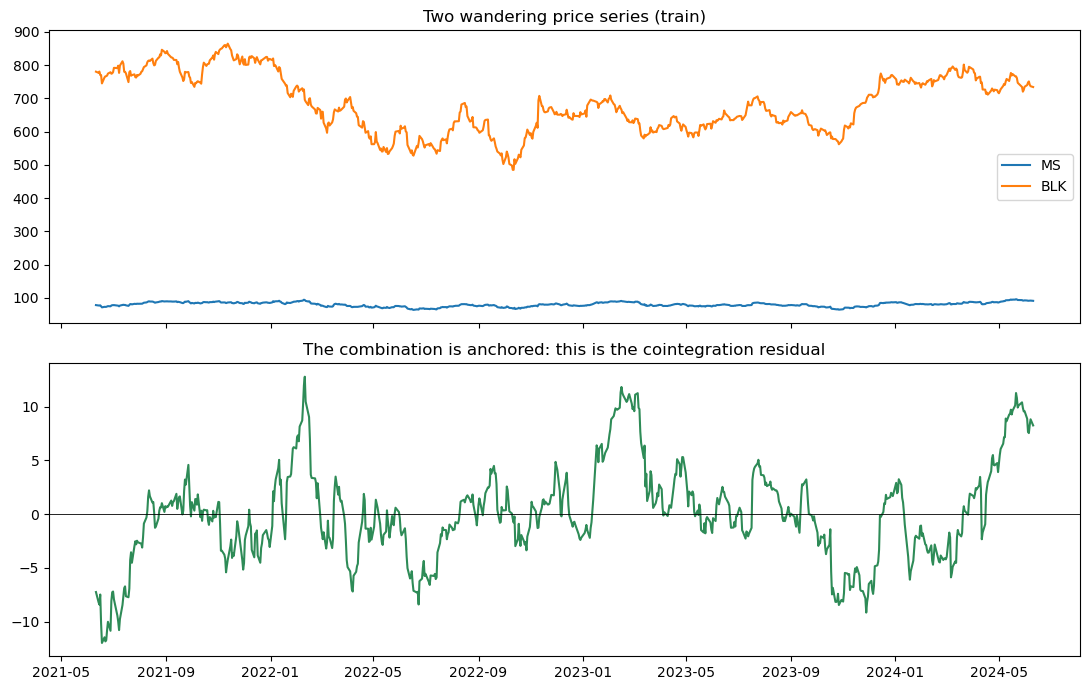

In [3]:
eg = cointegration.engle_granger(train[y_tkr], train[x_tkr])
print(f"OLS fit: {y_tkr} = {eg['alpha']:.2f} + {eg['beta']:.4f} * {x_tkr}")
print(f"Engle-Granger (MacKinnon) p-value: {eg['coint_pvalue']:.4f}  <- my gate")
print(f"naive residual ADF p-value:        {eg['resid_adf_pvalue']:.4f}  (flattering, shown for comparison)")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(train[y_tkr], label=y_tkr); axes[0].plot(train[x_tkr], label=x_tkr)
axes[0].legend(); axes[0].set_title("Two wandering price series (train)")
axes[1].plot(eg["resid"], color="seagreen")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_title("The combination is anchored: this is the cointegration residual")
plt.tight_layout(); plt.show()

## Step 3: Half-life. How fast does it come back?

A spread can be statistically mean-reverting but still useless to trade,
either *too slow* (I would sit in a position for a year while the
relationship has time to break) or *too fast* (the reversion finishes
before my next-day fill executes). I quantify the speed by fitting an
AR(1) on residual changes:

`delta_resid_t = lambda * resid_{t-1} + noise`

If lambda is negative, the residual gets pulled back toward zero, and the
half-life of a dislocation is `-ln(2)/ln(1+lambda)`. This comes from
treating the residual as a discretized Ornstein-Uhlenbeck process: after
one half-life, the expected remaining dislocation is half the original.

I keep pairs whose half-life is between **5 and 60 trading days**: long
enough that the move survives a one-day execution delay, short enough
that capital recycles and the train-period relationship plausibly still
holds while I am in the trade.

In [4]:
hl = cointegration.half_life(eg["resid"])
print(f"half-life of mean reversion: {hl:.1f} trading days")

half-life of mean reversion: 25.0 trading days


## The full scan

I run every same-sector pair (both orderings, keeping the better fit)
through all three steps on training data. Survivors are ranked by
Engle-Granger p-value, then half-life. I freeze the result to
`results/selected_pairs.json` and **never recompute it** on later data.

Why never? If I re-selected pairs on the test year, I would keep exactly
the pairs that happened to remain cointegrated and drop the ones that
broke. That decision uses information a real trader would not have had,
and it is look-ahead bias at the portfolio level even though no single
price was peeked at.

In [5]:
pairs = cointegration.select_pairs(train)
pairs[["sector", "y", "x", "beta", "coint_pvalue", "resid_adf_pvalue",
       "half_life"]].round(4)

,sector,y,x,beta,coint_pvalue,resid_adf_pvalue,half_life
0,Financials,MS,BLK,0.0576,0.0114,0.0024,24.9878
1,Energy,EOG,COP,0.9160,0.0169,0.0038,15.0328
2,Financials,MS,C,0.6182,0.0194,0.0044,22.5840
3,Consumer,PEP,TGT,-0.2035,0.0205,0.0047,21.2802
4,Consumer,PEP,NKE,-0.3072,0.0230,0.0054,23.5642
5,Energy,MPC,PSX,1.5742,0.0309,0.0076,30.7688
6,Technology,AMD,META,0.2556,0.0380,0.0097,26.5440
7,Consumer,KO,NKE,-0.0959,0.0464,0.0123,23.7274


### A non-cointegrated pair, for contrast

Same sector, both legs non-stationary, but no stable combination exists:
the "residual" itself wanders. This is exactly what Step 2 filters out.
If I traded this spread with z-scores anyway, every "dislocation" would
just be the residual drifting to a new level, and my mean-reversion bets
would have no statistical basis.

AAPL~NVDA Engle-Granger p-value: 0.144 (not cointegrated)


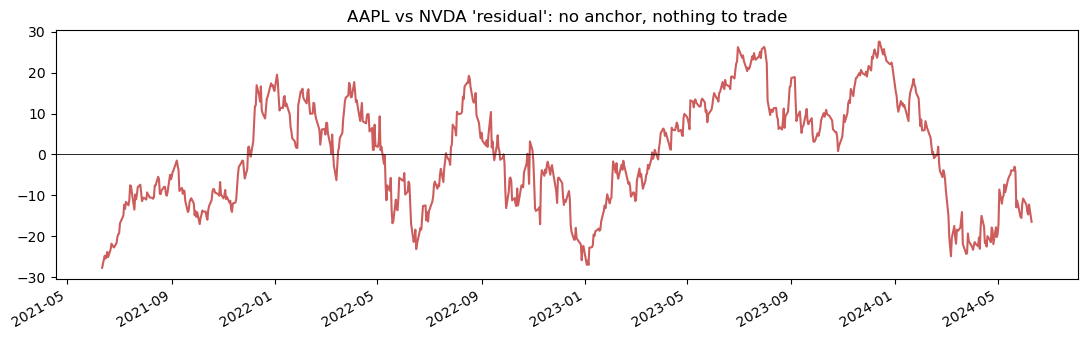

In [6]:
bad = cointegration.engle_granger(train["AAPL"], train["NVDA"])
print(f"AAPL~NVDA Engle-Granger p-value: {bad['coint_pvalue']:.3f} (not cointegrated)")
bad["resid"].plot(figsize=(11, 3.5), color="indianred",
                  title="AAPL vs NVDA 'residual': no anchor, nothing to trade")
plt.axhline(0, color="k", lw=0.6); plt.tight_layout(); plt.show()